# Hybrid Ensemble Learning with PSI and DRZ for Lung Cancer Prediction


### ___________________________________________________________________________________________________

### ___________________________________________________________________________________________________

# Introduction


# Problem statement

# Project objectives


### 1. Develop a hybrid ensemble learning model for lung cancer prediction using machine learning techniques.
### 2. Optimize and evaluate the models using appropriate performance metrics and threshold optimization.
### 3. Improve model reliability and explainability using PSI, DRZ, SHAP, and counterfactual analysis.



### ___________________________________________________________________________________________________

# Research Methodology

### Base Classifiers:
SVM 
Random Forest 
XGBoost 

### Ensemble Techniques:
Stacking Ensemble 
Soft Voting 

### Meta-Learner:
Logistic Regression 

### ___________________________________________________________________________________________________

# Explainable AI – XAI

### 1. PSI
Uses Mahalanobis Distance 
Identifies similar patients 

### 2. DRZ
Confidence levels: 
High 
Medium 
Low 

### 3. SHAP
Feature contribution explanation
 
### 4. Counterfactual Explanation
Minimal changes to reduce risk


### ___________________________________________________________________________________________________

# Dataset Overview

## dataset has 460,292 


# Libraries

In [28]:
#%pip install xgboost

In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import pandas as pd
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

In [30]:
lung_cancer = pd.read_csv("lung_cancer_prediction (1).csv")

In [31]:
print("Dataset shape:", lung_cancer.shape)
lung_cancer.head()

Dataset shape: (460292, 25)


,Country,Age,Gender,Smoking_Status,Second_Hand_Smoke,Air_Pollution_Exposure,Occupation_Exposure,Rural_or_Urban,Socioeconomic_Status,Healthcare_Access,...,Treatment_Access,Clinical_Trial_Access,Language_Barrier,Mortality_Risk,5_Year_Survival_Probability,Delay_in_Diagnosis,Family_History,Indoor_Smoke_Exposure,Tobacco_Marketing_Exposure,Final_Prediction
0,Russia,82,Male,Former Smoker,Yes,Medium,No,Urban,High,Limited,...,Partial,Yes,No,0.263278,0.797576,Yes,No,No,No,No
1,Thailand,66,Female,Former Smoker,No,High,No,Rural,Middle,Good,...,Partial,Yes,No,0.154697,0.336674,Yes,No,No,Yes,No
2,Colombia,87,Male,Former Smoker,No,Medium,No,Urban,Low,Poor,...,Partial,Yes,No,0.607435,0.063621,No,No,No,Yes,No
3,Egypt,51,Female,Former Smoker,No,Low,Yes,Rural,High,Good,...,Full,No,No,0.081184,0.336814,No,No,No,Yes,No
4,DR Congo,43,Male,Former Smoker,No,High,No,Urban,Middle,Good,...,Full,No,No,0.643276,0.820103,No,No,No,No,No


In [32]:
print("Missing values:")
print(lung_cancer.isnull().sum())

Missing values:
Country                             0
Age                                 0
Gender                              0
Smoking_Status                      0
Second_Hand_Smoke                   0
Air_Pollution_Exposure              0
Occupation_Exposure                 0
Rural_or_Urban                      0
Socioeconomic_Status                0
Healthcare_Access                   0
Insurance_Coverage                  0
Screening_Availability              0
Stage_at_Diagnosis                  0
Cancer_Type                         0
Mutation_Type                  138173
Treatment_Access                46053
Clinical_Trial_Access               0
Language_Barrier                    0
Mortality_Risk                      0
5_Year_Survival_Probability         0
Delay_in_Diagnosis                  0
Family_History                      0
Indoor_Smoke_Exposure               0
Tobacco_Marketing_Exposure          0
Final_Prediction                    0
dtype: int64


In [33]:
print("\nDuplicate rows:", lung_cancer.duplicated().sum())


Duplicate rows: 0


In [34]:
print("\nTarget distribution:")
print(lung_cancer["Final_Prediction"].value_counts())

print("\nTarget percentage:")
print(lung_cancer["Final_Prediction"].value_counts(normalize=True) * 100)


Target distribution:
Final_Prediction
No     368107
Yes     92185
Name: count, dtype: int64

Target percentage:
Final_Prediction
No     79.972496
Yes    20.027504
Name: proportion, dtype: float64


In [35]:
features = [
    "Age",
    "Gender",
    "Smoking_Status",
    "Second_Hand_Smoke",
    "Air_Pollution_Exposure",
    "Occupation_Exposure",
    "Healthcare_Access",
    "Screening_Availability",
    "Family_History",
    "Indoor_Smoke_Exposure",
    "Tobacco_Marketing_Exposure"
]

target = "Final_Prediction"

X = lung_cancer[features]
y = lung_cancer[target]
X.shape

(460292, 11)

<Figure size 1000x1500 with 0 Axes>

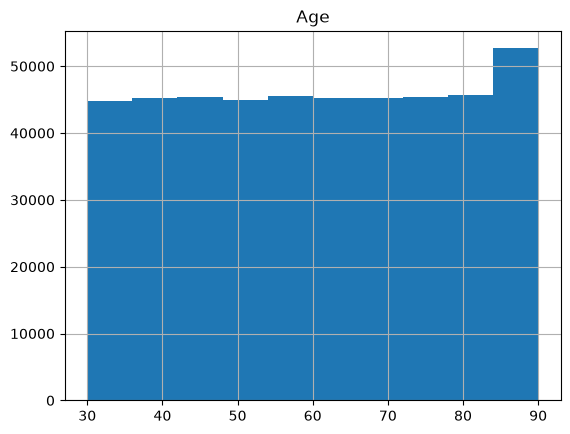

In [36]:
# Plot histograms for all columns
plt.figure(figsize=(10 , 15))
lung_cancer[features].hist()
plt.show()

In [37]:
# Numerical and categorical features
numerical_features = ["Age"]

categorical_features = [
    "Gender",
    "Smoking_Status",
    "Second_Hand_Smoke",
    "Air_Pollution_Exposure",
    "Occupation_Exposure",
    "Healthcare_Access",
    "Screening_Availability",
    "Family_History",
    "Indoor_Smoke_Exposure",
    "Tobacco_Marketing_Exposure"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


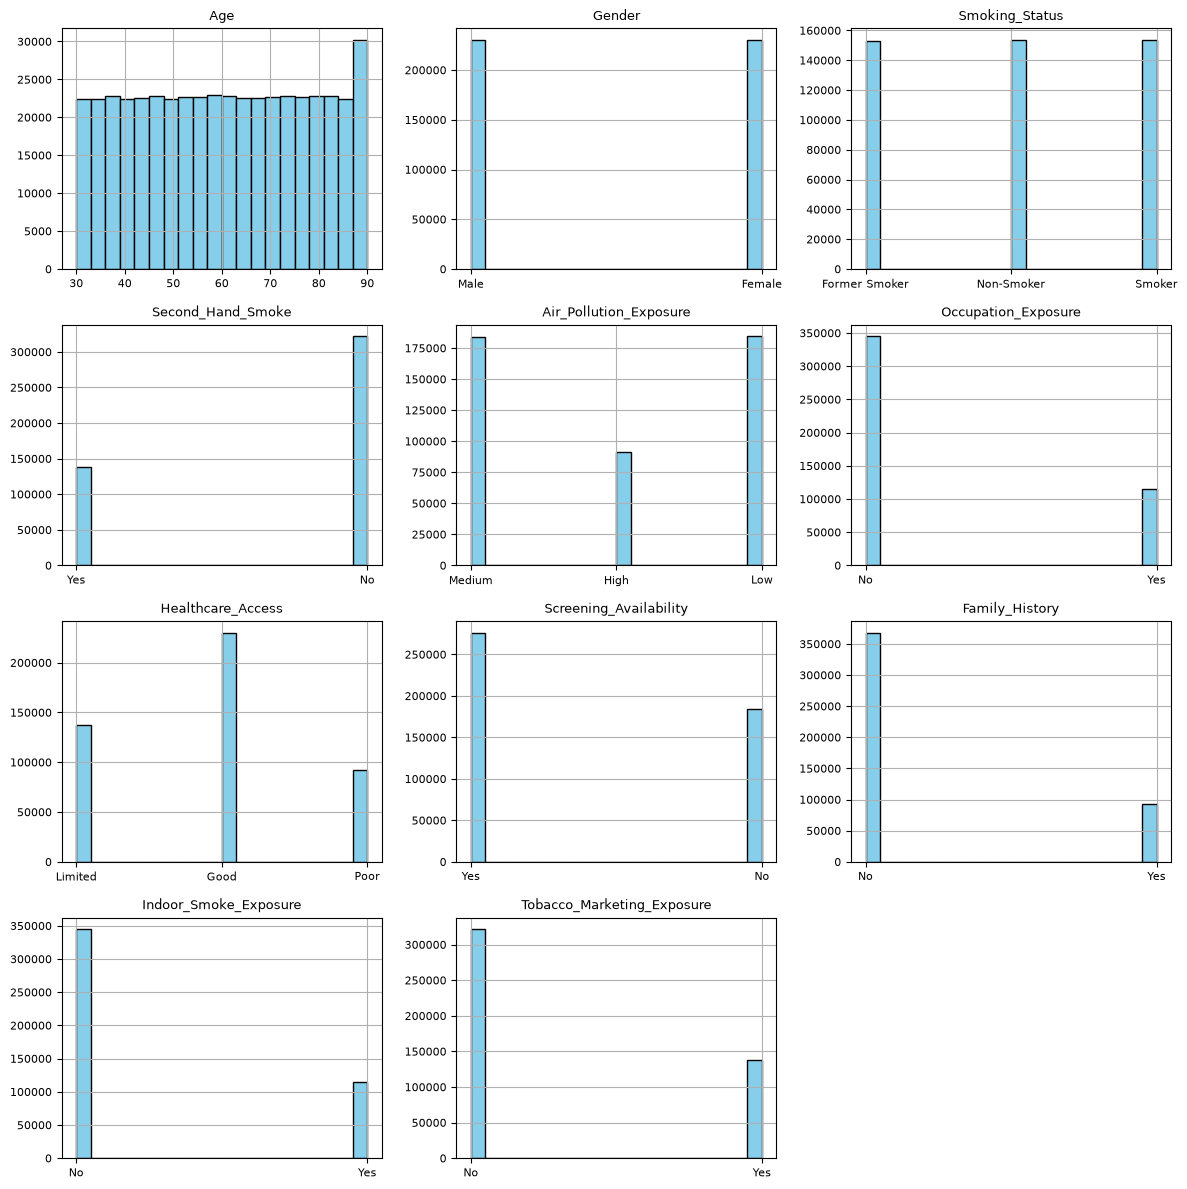

In [38]:
import matplotlib.pyplot as plt
import math

ncols = 3
nrows = math.ceil(len(features) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, 3 * nrows)
)

axes = axes.flatten()

for ax, feature in zip(axes, features):
    lung_cancer[feature].hist(
        ax=ax,
        bins=20,
        color='skyblue',
        edgecolor='black'
    )
    ax.set_title(feature, fontsize=9)
    ax.tick_params(labelsize=8)


for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

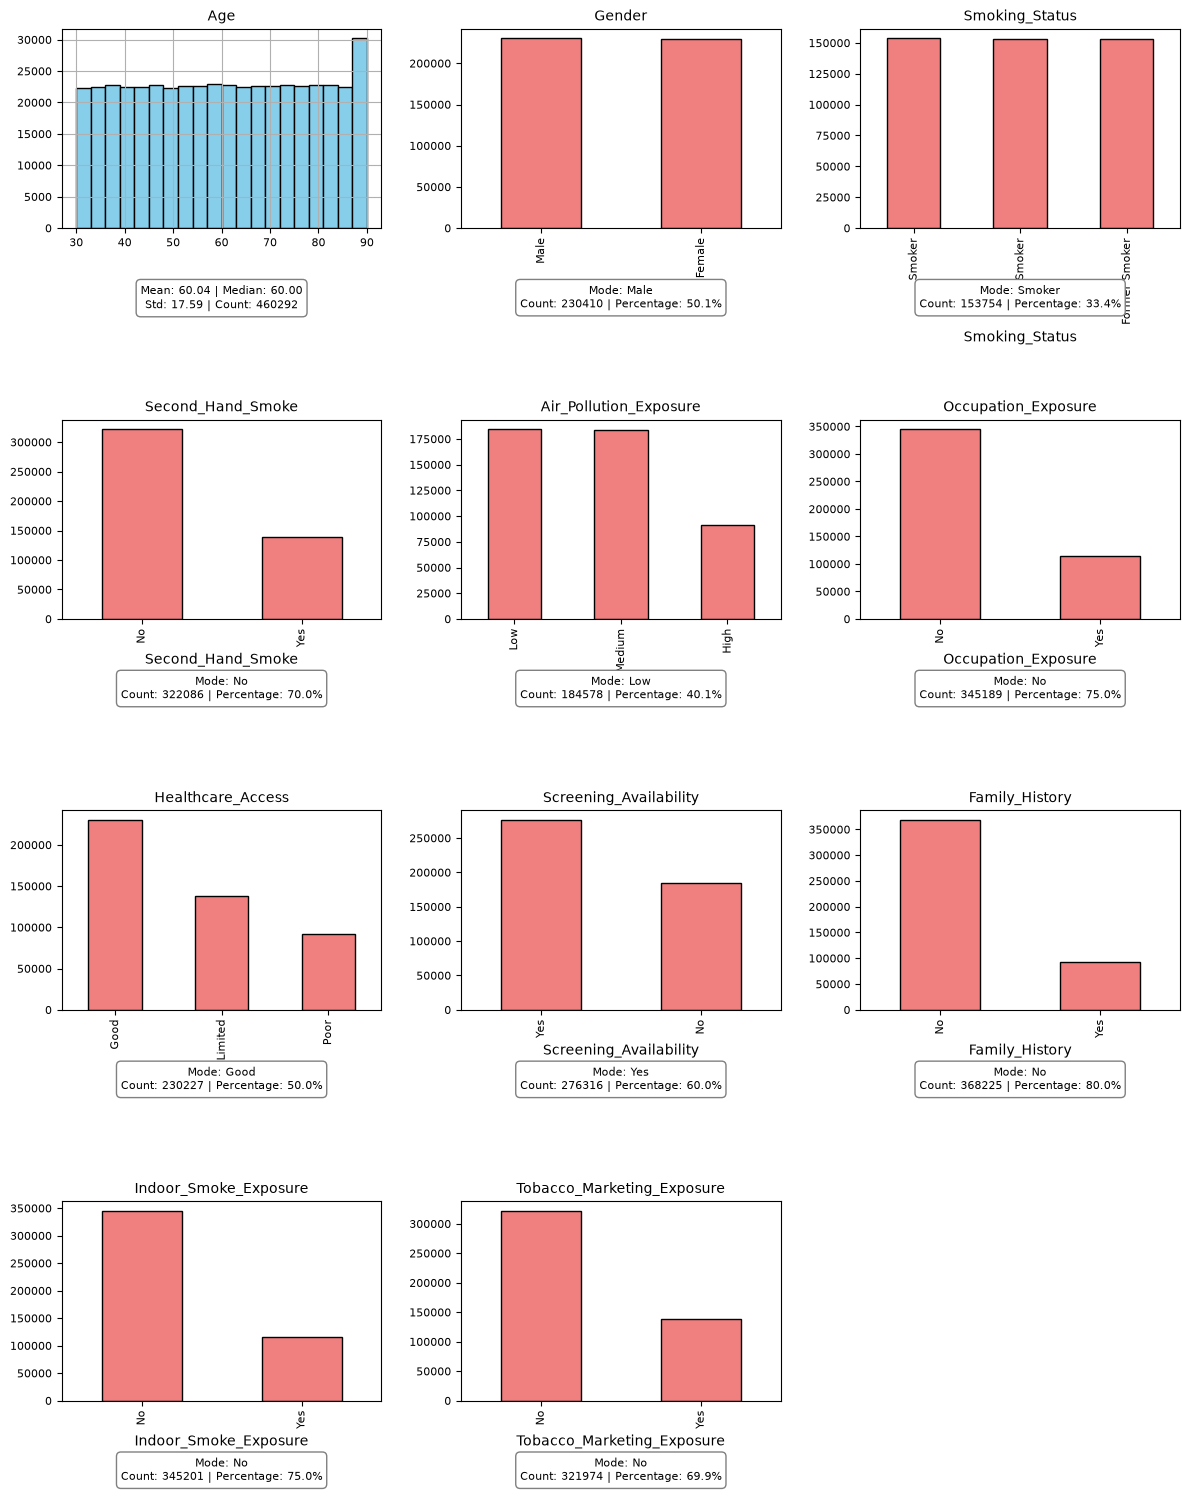

In [39]:
ncols = 3
nrows = math.ceil(len(features) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, 3.8 * nrows)
)

axes = axes.flatten()

for ax, feature in zip(axes, features):
    data = lung_cancer[feature].dropna()

    if data.empty:
        ax.set_title(feature, fontsize=10)
        ax.text(0.5, 0.5, "No data",
                ha='center', va='center',
                transform=ax.transAxes)
        ax.axis('off')
        continue


    if pd.api.types.is_numeric_dtype(data):
        data.hist(
            ax=ax,
            bins=20,
            color='skyblue',
            edgecolor='black'
        )

        summary = (
            f"Mean: {data.mean():.2f} | "
            f"Median: {data.median():.2f}\n"
            f"Std: {data.std():.2f} | "
            f"Count: {data.count()}"
        )

    else:
        counts = data.astype(str).value_counts()
        counts.plot(
            kind='bar',
            ax=ax,
            color='lightcoral',
            edgecolor='black'
        )

        most_common = counts.index[0]
        frequency = counts.iloc[0]
        percentage = frequency / counts.sum() * 100

        summary = (
            f"Mode: {most_common}\n"
            f"Count: {frequency} | "
            f"Percentage: {percentage:.1f}%"
        )

    ax.set_title(feature, fontsize=10)
    ax.tick_params(axis='both', labelsize=8)
    
    ax.text(
        0.5, -0.28,
        summary,
        transform=ax.transAxes,
        ha='center',
        va='top',
        fontsize=8,
        bbox=dict(
            facecolor='white',
            edgecolor='gray',
            boxstyle='round,pad=0.4'
        )
    )


for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout(h_pad=4, w_pad=2)
plt.show()

In [40]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,stratify=y)

In [41]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

Training set: (368233, 11)
Testing set: (92059, 11)
Training target distribution:
Final_Prediction
No     0.799725
Yes    0.200275
Name: proportion, dtype: float64


In [42]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        class_weight=None,
        random_state=42,
        max_iter=3000
    ))
])

print("Training Linear SVM...")
svm_model.fit(X_train, y_train)

print("Training completed successfully!")

Training Linear SVM...
Training completed successfully!


In [43]:
from sklearn.metrics import classification_report
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

          No       0.80      1.00      0.89     73622
         Yes       0.00      0.00      0.00     18437

    accuracy                           0.80     92059
   macro avg       0.40      0.50      0.44     92059
weighted avg       0.64      0.80      0.71     92059



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [44]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC  

# Define models
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        random_state=42,       
        max_iter=10000           
    ))
])

# Train models
print("Training LinearSVC...")
svm_model.fit(X_train, y_train)
print("Training completed successfully!")

Training LinearSVC...
Training completed successfully!


In [45]:
rf_model = Pipeline([
    ("preprocessor", preprocessor), 
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",      
        n_jobs=-1
    
])

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Training completed!")

# التقييم
y_pred_rf = rf_model.predict(X_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("-" * 40)
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Training Random Forest...
Training completed!
Confusion Matrix:
[[43448 30174]
 [10714  7723]]
----------------------------------------
Classification Report:
              precision    recall  f1-score   support

          No       0.80      0.59      0.68     73622
         Yes       0.20      0.42      0.27     18437

    accuracy                           0.56     92059
   macro avg       0.50      0.50      0.48     92059
weighted avg       0.68      0.56      0.60     92059



In [46]:
# Define models
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train models
print("Training Random Forest...")
rf_model.fit(X_train, y_train)


print("Training completed successfully!")

Training Random Forest...
Training completed successfully!


In [47]:
# Define models
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])


In [48]:
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})
y_test_encoded = y_test.map({'No': 0, 'Yes': 1})



print("Training XGBoost...")
xgb_model.fit(X_train, y_train_encoded)
print("Training completed successfully!")

Training XGBoost...
Training completed successfully!


In [49]:
y_pred_xgb = xgb_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_xgb))
print("-" * 40)
print("Classification Report:")
print(classification_report(y_test_encoded, y_pred_xgb))

Confusion Matrix:
[[73622     0]
 [18437     0]]
----------------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     73622
           1       0.00      0.00      0.00     18437

    accuracy                           0.80     92059
   macro avg       0.40      0.50      0.44     92059
weighted avg       0.64      0.80      0.71     92059



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
